# 13 — Model Explainability & SHAP Analysis

**Objective:** Compute global and local feature explanations:
- SHAP TreeExplainer for CO and NOx models.
- Generate and save SHAP summary beeswarm plots.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

def find_root():
    p = Path.cwd()
    for parent in [p] + list(p.parents):
        if (parent / 'data' / 'raw' / 'gt_2011.csv').exists():
            return parent
    return p

ROOT = find_root()
sys.path.insert(0, str(ROOT))

from src.models.model_factory import create_model
from src.data.loader import FEATURES_A
from src.data.splitting import temporal_split


D:\TURBINE_X_Full_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Computing SHAP Values for CO and NOx


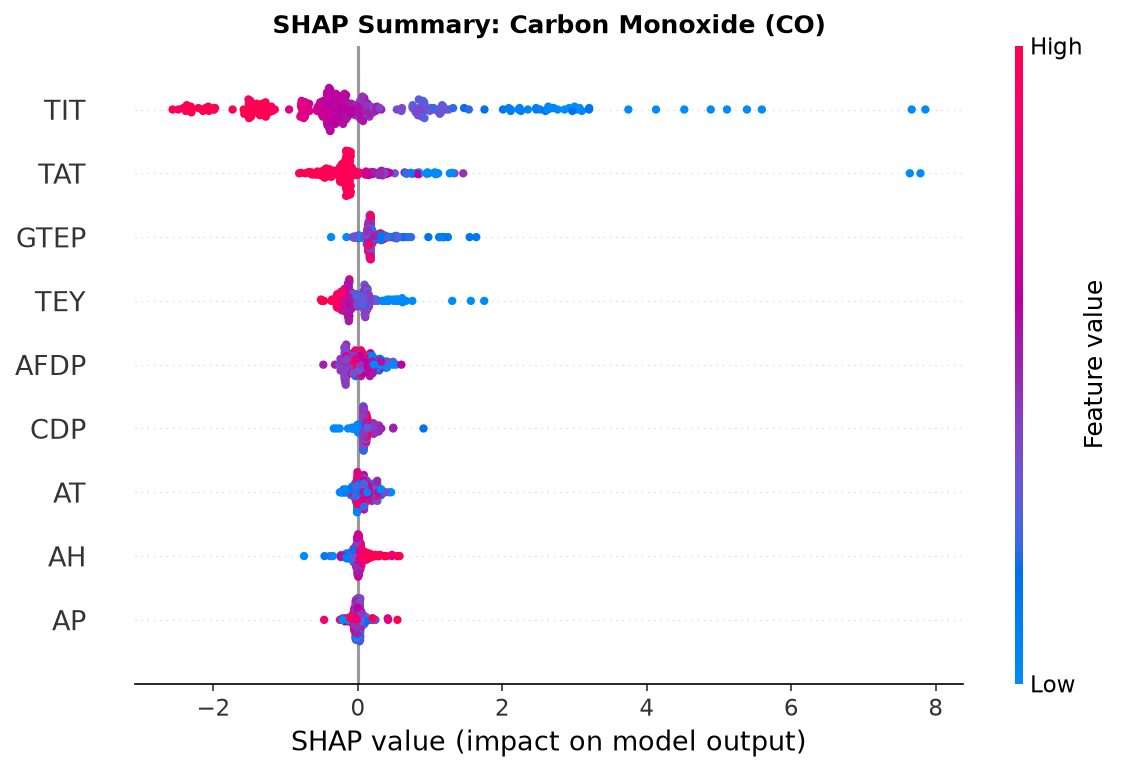

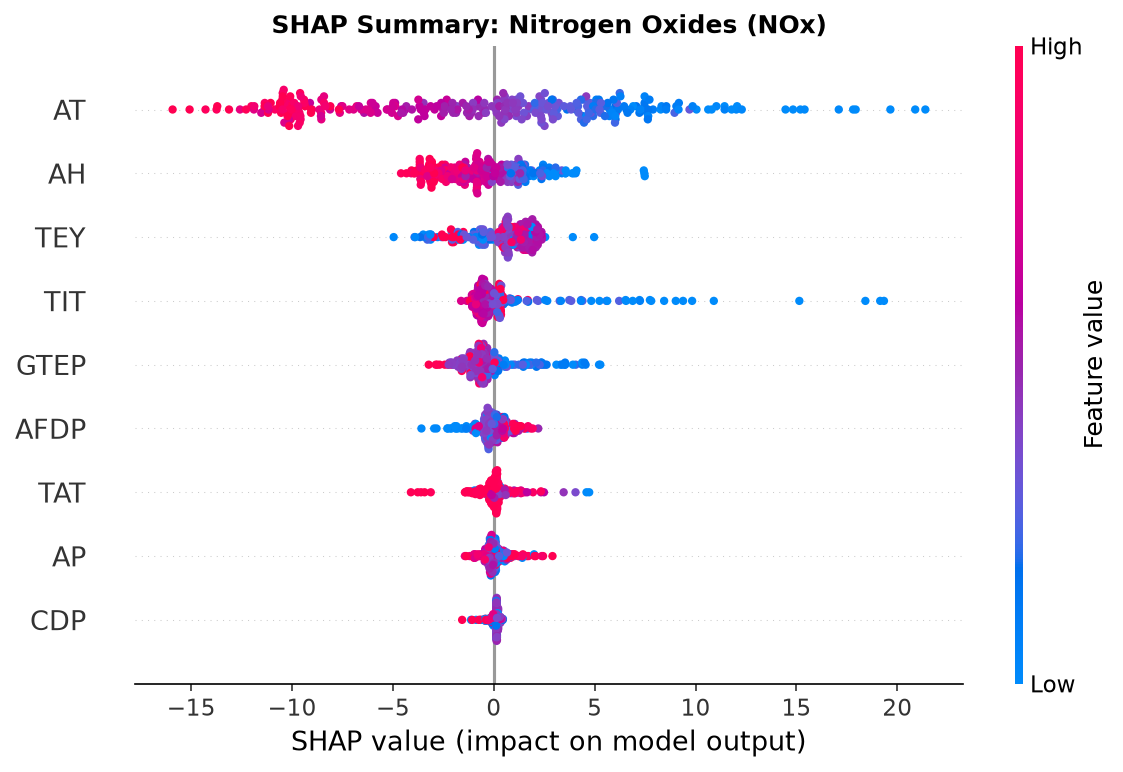

Saved SHAP summary plots to outputs\figures\shap_summary_co.png and outputs\figures\shap_summary_nox.png
Model explainability analysis COMPLETE.


In [2]:
df = pd.read_parquet(ROOT / "data" / "processed" / "cleaned_master.parquet")
dev, cal, test = temporal_split(df)

# Train single-target tree models for SHAP TreeExplainer
from sklearn.ensemble import HistGradientBoostingRegressor

reg_co = HistGradientBoostingRegressor(max_iter=80, random_state=42)
reg_co.fit(dev[FEATURES_A], dev["CO"])

reg_nox = HistGradientBoostingRegressor(max_iter=80, random_state=42)
reg_nox.fit(dev[FEATURES_A], dev["NOX"])

sample = cal[FEATURES_A].sample(300, random_state=42)

explainer_co = shap.TreeExplainer(reg_co)
shap_values_co = explainer_co.shap_values(sample)

explainer_nox = shap.TreeExplainer(reg_nox)
shap_values_nox = explainer_nox.shap_values(sample)

# 1. SHAP CO Summary Plot
fig1 = plt.figure(figsize=(10, 6), dpi=150)
shap.summary_plot(shap_values_co, sample, show=False)
plt.title("SHAP Summary: Carbon Monoxide (CO)", fontweight="bold")
out_shap_co = ROOT / "outputs" / "figures" / "shap_summary_co.png"
out_shap_co.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_shap_co, dpi=200, bbox_inches="tight")
plt.show()

# 2. SHAP NOx Summary Plot
fig2 = plt.figure(figsize=(10, 6), dpi=150)
shap.summary_plot(shap_values_nox, sample, show=False)
plt.title("SHAP Summary: Nitrogen Oxides (NOx)", fontweight="bold")
out_shap_nox = ROOT / "outputs" / "figures" / "shap_summary_nox.png"
plt.savefig(out_shap_nox, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved SHAP summary plots to {out_shap_co.relative_to(ROOT)} and {out_shap_nox.relative_to(ROOT)}")
print("Model explainability analysis COMPLETE.")
